# Notebook 1 — Data Cleaning & Preprocessing

**MoveInSync FDE Case Study**

This notebook validates, deduplicates, cleans, and enriches the raw Google Play reviews dataset.

---

## 0. Setup & Imports

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os, sys, re, json
from pathlib import Path
from datetime import datetime, timezone

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "#F8F9FA",
                             "axes.grid": True, "grid.color": "#E0E0E0", "font.size": 11})
import seaborn as sns

BASE_DIR = Path("..").resolve()
RAW_CSV  = BASE_DIR / "data" / "raw" / "google_play_reviews.csv"
CLEAN_CSV = BASE_DIR / "data" / "processed" / "google_play_reviews_clean.csv"
FIGURES  = BASE_DIR / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

print(f"Base dir  : {BASE_DIR}")
print(f"Raw CSV   : {RAW_CSV}")
print(f"Exists    : {RAW_CSV.exists()}")


Base dir  : D:\moviensnyc\moveinsync-fde-case-study
Raw CSV   : D:\moviensnyc\moveinsync-fde-case-study\data\raw\google_play_reviews.csv
Exists    : True


## 1. Load Raw Dataset

In [2]:
df_raw = pd.read_csv(RAW_CSV, dtype=str, low_memory=False)
print(f"Shape: {df_raw.shape}")
df_raw.head(3)


Shape: (10144, 16)


,review_id,app_id,review_text,star_rating,review_date,review_date_ts,last_updated,app_version,reviewer_id_hash,developer_reply,developer_reply_date,language,country,source_platform,sort_order,collection_timestamp
0,60798e45-939e-4a99-8f5b-17383a891db6,com.moveinsync.ets,"whenever i update this app, i am not able to o...",1,2026-10-09T10:55:03,1791523503.0,NaN,NaN,6058644320622310,NaN,NaN,en,in,google_play,NEWEST,2026-10-10T07:44:01.612046+00:00
1,25c29e24-3832-4411-842b-8fb741ae64b7,com.moveinsync.ets,good,5,2026-10-09T09:14:34,1791517474.0,NaN,12.19.0,2f773f25a2e75e8b,NaN,NaN,en,in,google_play,NEWEST,2026-10-10T07:44:01.612046+00:00
2,7476b129-f0da-458e-8f86-d77ba2f9a710,com.moveinsync.ets,MoveOutSync doesn't plan commutes; it plans cr...,1,2026-10-09T08:22:55,1791514375.0,NaN,12.19.0,7b56affacc72d077,NaN,NaN,en,in,google_play,NEWEST,2026-10-10T07:44:01.612046+00:00


### 1.1 Schema Overview

In [3]:
df_raw.dtypes.to_frame("dtype").assign(
    null_count=df_raw.isnull().sum(),
    empty_count=(df_raw == "").sum(),
    sample=df_raw.iloc[0]
)


,dtype,null_count,empty_count,sample
review_id,object,0,0,60798e45-939e-4a99-8f5b-17383a891db6
app_id,object,0,0,com.moveinsync.ets
review_text,object,0,0,"whenever i update this app, i am not able to o..."
star_rating,object,0,0,1
review_date,object,0,0,2026-10-09T10:55:03
review_date_ts,object,0,0,1791523503.0
last_updated,object,6902,0,NaN
app_version,object,880,0,NaN
reviewer_id_hash,object,0,0,6058644320622310
developer_reply,object,6902,0,NaN


## 2. Data Quality Audit

In [4]:
total = len(df_raw)

print("=== DATA QUALITY AUDIT ===")
print(f"Total rows     : {total:,}")
print(f"Total columns  : {df_raw.shape[1]}")
print()

# Missing values
missing = df_raw.isnull().sum() + (df_raw == "").sum()
missing_pct = (missing / total * 100).round(2)
quality_df = pd.DataFrame({"missing": missing, "missing_pct": missing_pct})
print("Missing values per column:")
print(quality_df[quality_df["missing"] > 0].to_string())


=== DATA QUALITY AUDIT ===
Total rows     : 10,144
Total columns  : 16

Missing values per column:
                      missing  missing_pct
last_updated             6902        68.04
app_version               880         8.68
developer_reply          6902        68.04
developer_reply_date     6902        68.04


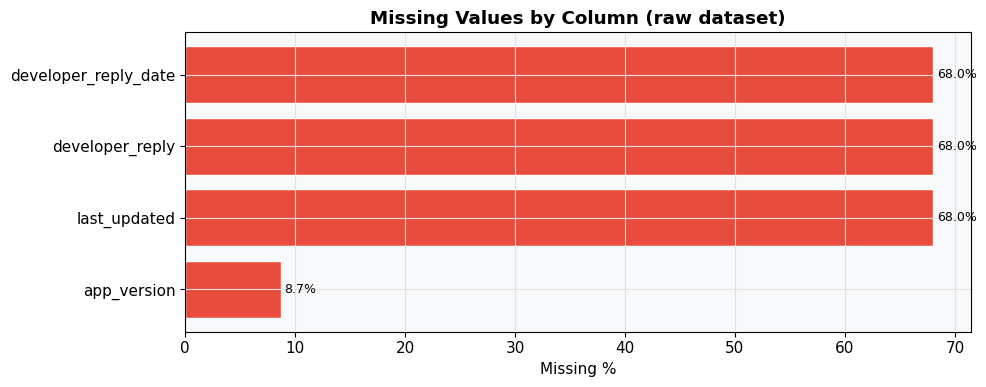

Chart saved.


In [5]:
# Visualise missing values
fig, ax = plt.subplots(figsize=(10, 4))
miss_plot = quality_df[quality_df["missing"] > 0].sort_values("missing_pct", ascending=True)
ax.barh(miss_plot.index, miss_plot["missing_pct"], color="#E74C3C", edgecolor="white")
ax.set_xlabel("Missing %")
ax.set_title("Missing Values by Column (raw dataset)", fontweight="bold")
for i, (val, idx) in enumerate(zip(miss_plot["missing_pct"], miss_plot.index)):
    ax.text(val + 0.3, i, f"{val:.1f}%", va="center", fontsize=9)
plt.tight_layout()
plt.savefig(FIGURES / "nb1_missing_values.png", dpi=150, bbox_inches="tight")
plt.show()
print("Chart saved.")


## 3. Deduplication

In [6]:
print(f"Before dedup: {len(df_raw):,} rows")

# Step 1: Dedup by review_id
df = df_raw.copy()
df["review_id"] = df["review_id"].replace("", np.nan)
dup_id_count = df[df["review_id"].notna()].duplicated(subset=["review_id"]).sum()
df = df.drop_duplicates(subset=["review_id"], keep="first")
print(f"Duplicate review_ids removed: {dup_id_count}")

# Step 2: Dedup by (text, date) for rows missing review_id
no_id = df["review_id"].isna()
if no_id.sum() > 0:
    df_no_id = df[no_id].drop_duplicates(subset=["review_text","review_date"], keep="first")
    df = pd.concat([df[~no_id], df_no_id], ignore_index=True)
    print(f"Text+date duplicates removed (no-ID group): {no_id.sum() - len(df_no_id)}")

print(f"After dedup: {len(df):,} rows")


Before dedup: 10,144 rows
Duplicate review_ids removed: 0
After dedup: 10,144 rows


## 4. Type Casting & Rating Validation

In [7]:
# Cast star_rating
df["star_rating"] = pd.to_numeric(df["star_rating"], errors="coerce")
invalid_ratings = (~df["star_rating"].isin([1,2,3,4,5])).sum()
print(f"Invalid ratings: {invalid_ratings}")
df = df[df["star_rating"].isin([1,2,3,4,5])].copy()

# Parse dates
df["review_date_parsed"] = pd.to_datetime(df["review_date"], utc=True, errors="coerce")
bad_dates = df["review_date_parsed"].isna().sum()
print(f"Date parse failures: {bad_dates}")

# Text lengths
df["review_text"] = df["review_text"].fillna("").astype(str).str.strip()
df["text_length"]  = df["review_text"].str.len()
print(f"Empty texts: {(df['text_length']==0).sum()}")
print(f"Short texts (1-4 chars): {((df['text_length']>0)&(df['text_length']<5)).sum()}")

df.head(2)


Invalid ratings: 0
Date parse failures: 0
Empty texts: 0
Short texts (1-4 chars): 994


,review_id,app_id,review_text,star_rating,review_date,review_date_ts,last_updated,app_version,reviewer_id_hash,developer_reply,developer_reply_date,language,country,source_platform,sort_order,collection_timestamp,review_date_parsed,text_length
0,60798e45-939e-4a99-8f5b-17383a891db6,com.moveinsync.ets,"whenever i update this app, i am not able to o...",1,2026-10-09T10:55:03,1791523503.0,NaN,NaN,6058644320622310,NaN,NaN,en,in,google_play,NEWEST,2026-10-10T07:44:01.612046+00:00,2026-10-09 10:55:03+00:00,138
1,25c29e24-3832-4411-842b-8fb741ae64b7,com.moveinsync.ets,good,5,2026-10-09T09:14:34,1791517474.0,NaN,12.19.0,2f773f25a2e75e8b,NaN,NaN,en,in,google_play,NEWEST,2026-10-10T07:44:01.612046+00:00,2026-10-09 09:14:34+00:00,4


## 5. Date Range & Monthly Coverage

Date range: 2018-09-12 → 2026-10-09


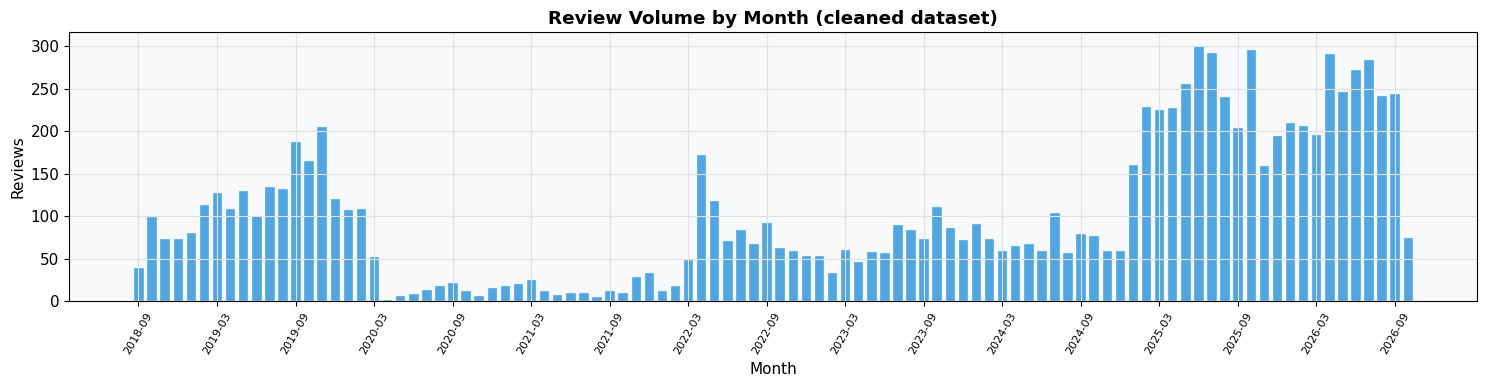

In [8]:
print(f"Date range: {df['review_date_parsed'].min().date()} → {df['review_date_parsed'].max().date()}")

df["year"]       = df["review_date_parsed"].dt.year
df["month"]      = df["review_date_parsed"].dt.month
df["year_month"] = df["review_date_parsed"].dt.to_period("M").astype(str)

monthly = df.groupby("year_month").size().reset_index(name="count")

fig, ax = plt.subplots(figsize=(15, 4))
ax.bar(monthly["year_month"], monthly["count"], color="#3498DB", edgecolor="white", alpha=0.85)
ax.set_title("Review Volume by Month (cleaned dataset)", fontweight="bold")
ax.set_xlabel("Month"); ax.set_ylabel("Reviews")
ax.tick_params(axis="x", rotation=75)
# Only label every 6th month
ticks = monthly["year_month"].tolist()
ax.set_xticks(range(0, len(ticks), 6))
ax.set_xticklabels(ticks[::6], rotation=60, fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES / "nb1_monthly_volume.png", dpi=150, bbox_inches="tight")
plt.show()


## 6. Rating Distribution

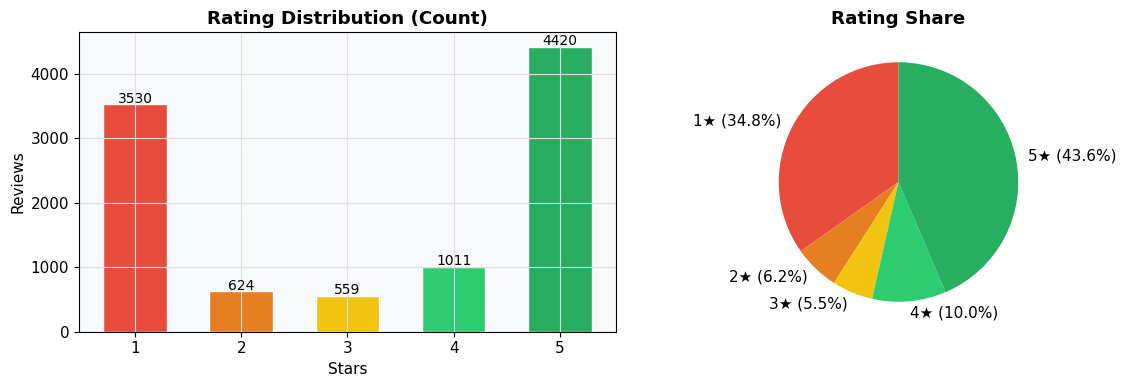

Mean: 3.21 | Median: 4.0 | Std: 1.80


In [9]:
PALETTE = {1:"#E74C3C", 2:"#E67E22", 3:"#F1C40F", 4:"#2ECC71", 5:"#27AE60"}
counts = df["star_rating"].value_counts().sort_index()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Bar
ax1.bar(counts.index, counts.values, color=[PALETTE[i] for i in counts.index], edgecolor="white", width=0.6)
ax1.set_title("Rating Distribution (Count)", fontweight="bold")
ax1.set_xlabel("Stars"); ax1.set_ylabel("Reviews")
for i, v in zip(counts.index, counts.values):
    ax1.text(i, v+20, str(v), ha="center", fontsize=10)

# Pie
ax2.pie(counts.values, labels=[f"{i}★ ({v/len(df)*100:.1f}%)" for i,v in zip(counts.index, counts.values)],
        colors=[PALETTE[i] for i in counts.index], startangle=90)
ax2.set_title("Rating Share", fontweight="bold")

plt.tight_layout()
plt.savefig(FIGURES / "nb1_rating_dist.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Mean: {df['star_rating'].mean():.2f} | Median: {df['star_rating'].median()} | Std: {df['star_rating'].std():.2f}")


## 7. App Version Coverage

In [10]:
df["app_version"] = df["app_version"].fillna("").astype(str)
n_with_ver = (df["app_version"] != "").sum()
n_versions  = df["app_version"].nunique()
print(f"Reviews with version info : {n_with_ver:,}  ({n_with_ver/len(df)*100:.1f}%)")
print(f"Unique app versions       : {n_versions}")
print()

# Top 15 versions by review count
top_versions = (df[df["app_version"]!=""]
               .groupby("app_version")
               .agg(count=("star_rating","count"), mean_rating=("star_rating","mean"))
               .sort_values("count", ascending=False).head(15))
print(top_versions.to_string())


Reviews with version info : 9,264  (91.3%)
Unique app versions       : 217

             count  mean_rating
app_version                    
11.5.17        357     3.383754
12.6           285     3.810526
12.1.2         258     3.573643
11.5.21        211     3.838863
11.4.13        202     2.688119
6.1            193     3.005181
6.8.7          172     2.412791
12.1           167     3.826347
12.3           153     3.640523
12.2.1         152     3.809211
12.0           147     3.761905
12.5           144     3.770833
11.5.19        144     3.805556
12.11.2        144     3.979167
11.3.9         143     2.510490


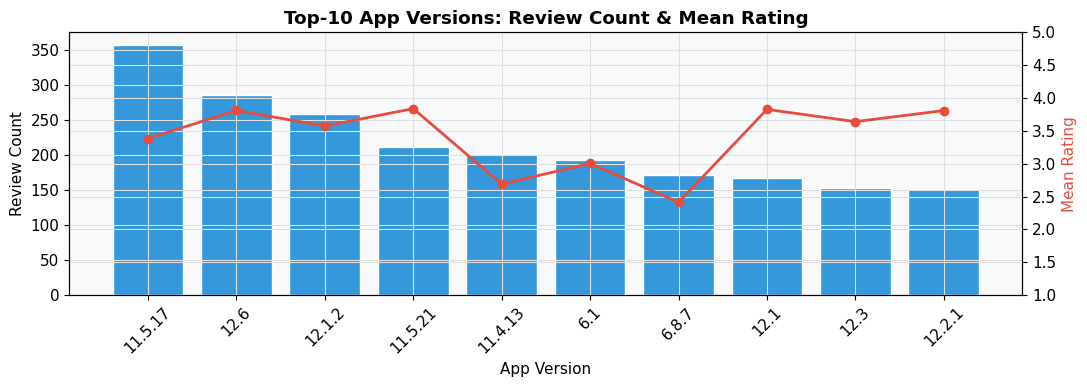

In [11]:
# Mean rating per top-10 version
top10 = top_versions.head(10).reset_index()
fig, ax = plt.subplots(figsize=(11, 4))
bars = ax.bar(top10["app_version"], top10["count"], color="#3498DB", edgecolor="white", label="Review Count")
ax2 = ax.twinx()
ax2.plot(top10["app_version"], top10["mean_rating"], color="#E74C3C", marker="o", linewidth=2, label="Mean Rating")
ax2.set_ylim(1, 5)
ax2.set_ylabel("Mean Rating", color="#E74C3C")
ax.set_ylabel("Review Count"); ax.set_xlabel("App Version")
ax.set_title("Top-10 App Versions: Review Count & Mean Rating", fontweight="bold")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig(FIGURES / "nb1_version_ratings.png", dpi=150, bbox_inches="tight")
plt.show()


## 8. Language Detection (Sample)

In [12]:
from langdetect import detect

def detect_safe(text):
    try: return detect(str(text)) if len(str(text)) > 10 else "unknown"
    except: return "unknown"

sample = df.sample(min(500, len(df)), random_state=42).copy()
sample["detected_lang"] = sample["review_text"].apply(detect_safe)
lang_counts = sample["detected_lang"].value_counts()
print("Language distribution (500-review sample):")
print(lang_counts.to_string())


Language distribution (500-review sample):
detected_lang
en         379
unknown     92
fr           5
no           4
af           4
ro           4
it           2
hr           2
da           2
de           2
nl           1
tl           1
et           1
es           1


## 9. Text Length Analysis

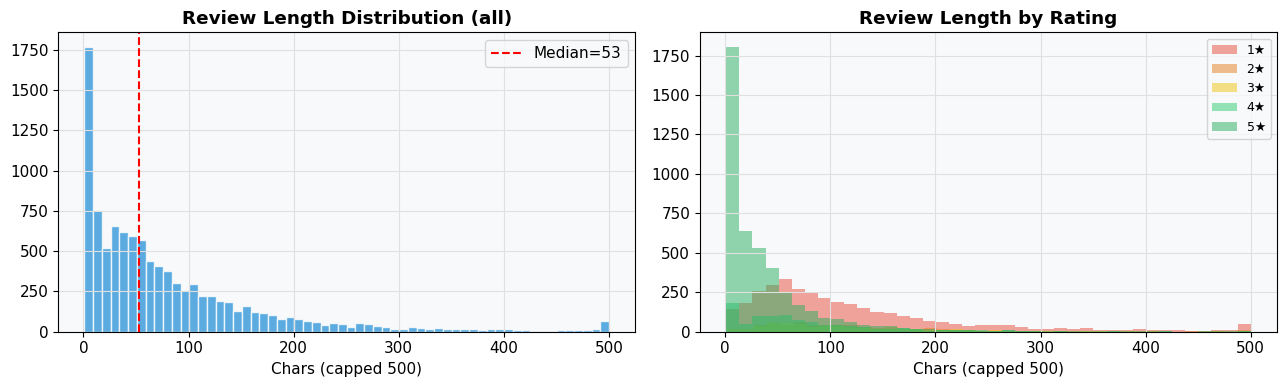

,count,mean,std,min,25%,50%,75%,max
star_rating,,,,,,,,
1,3530.0,121.6,103.6,1.0,51.0,91.0,157.0,663.0
2,624.0,127.9,97.8,3.0,63.0,104.0,162.0,499.0
3,559.0,123.1,96.4,2.0,54.0,94.0,163.0,500.0
4,1011.0,86.1,88.8,1.0,29.0,60.0,113.0,501.0
5,4420.0,39.2,54.9,1.0,8.0,20.0,48.0,511.0


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Overall
axes[0].hist(df["text_length"].clip(upper=500), bins=60, color="#3498DB", edgecolor="white", alpha=0.8)
axes[0].axvline(df["text_length"].median(), color="red", linestyle="--",
                label=f"Median={df['text_length'].median():.0f}")
axes[0].set_title("Review Length Distribution (all)", fontweight="bold")
axes[0].set_xlabel("Chars (capped 500)"); axes[0].legend()

# By rating
for r, color in PALETTE.items():
    sub = df[df["star_rating"]==r]["text_length"].clip(upper=500)
    axes[1].hist(sub, bins=40, alpha=0.5, label=f"{r}★", color=color)
axes[1].set_title("Review Length by Rating", fontweight="bold")
axes[1].set_xlabel("Chars (capped 500)"); axes[1].legend(fontsize=9)

plt.tight_layout()
plt.savefig(FIGURES / "nb1_text_length.png", dpi=150, bbox_inches="tight")
plt.show()

df.groupby("star_rating")["text_length"].describe().round(1)


## 10. Developer Reply Analysis

Developer reply rate by rating (%):
star_rating
1    45.2
2    50.2
3    43.6
4    32.0
5    17.3

Overall reply rate: 32.0%


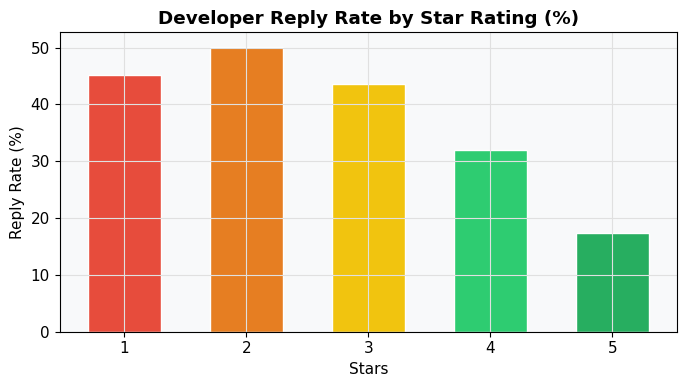

In [14]:
df["has_reply"] = df["developer_reply"].notna() & (df["developer_reply"].fillna("") != "")
reply_by_rating = df.groupby("star_rating")["has_reply"].mean() * 100
print("Developer reply rate by rating (%):")
print(reply_by_rating.round(1).to_string())
print(f"\nOverall reply rate: {df['has_reply'].mean()*100:.1f}%")

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(reply_by_rating.index, reply_by_rating.values,
       color=[PALETTE[i] for i in reply_by_rating.index], edgecolor="white", width=0.6)
ax.set_title("Developer Reply Rate by Star Rating (%)", fontweight="bold")
ax.set_xlabel("Stars"); ax.set_ylabel("Reply Rate (%)")
plt.tight_layout()
plt.savefig(FIGURES / "nb1_reply_rate.png", dpi=150, bbox_inches="tight")
plt.show()


## 11. Feature Engineering for ML

In [15]:
# Features that will be used in the ML model
df["review_year"]   = df["review_date_parsed"].dt.year
df["review_month"]  = df["review_date_parsed"].dt.month
df["review_dow"]    = df["review_date_parsed"].dt.dayofweek  # 0=Mon
df["has_reply"]     = df["has_reply"].astype(int)
df["is_low_star"]   = (df["star_rating"] <= 2).astype(int)
df["is_high_star"]  = (df["star_rating"] >= 4).astype(int)
df["sentiment_label"] = df["star_rating"].map({1:"negative",2:"negative",3:"neutral",4:"positive",5:"positive"})

# Clean text for NLP
import re
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["review_text_clean"] = df["review_text"].apply(clean_text)

print("Feature-engineered columns added:")
new_cols = ["review_year","review_month","review_dow","has_reply","is_low_star","is_high_star",
            "sentiment_label","review_text_clean"]
print(df[new_cols].head(3).to_string())


Feature-engineered columns added:
   review_year  review_month  review_dow  has_reply  is_low_star  is_high_star sentiment_label                                                                                                                                                                                                                                                                                                                                                                                                                                                    review_text_clean
0         2026            10           4          0            1             0        negative                                                                                                                                                                                                                                                                                                                                when

## 12. Save Clean Dataset

In [16]:
CLEAN_CSV.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(CLEAN_CSV, index=False, encoding="utf-8")
print(f"Clean dataset saved: {CLEAN_CSV}")
print(f"Shape: {df.shape}")
print()
print("=== CLEANING SUMMARY ===")
print(f"Raw records       : {len(df_raw):,}")
print(f"Duplicate IDs rm  : {dup_id_count}")
print(f"Invalid ratings rm: {invalid_ratings}")
print(f"Clean records     : {len(df):,}")
print(f"Retention rate    : {len(df)/len(df_raw)*100:.1f}%")
print(f"Date range        : {df['review_date_parsed'].min().date()} → {df['review_date_parsed'].max().date()}")
print(f"Mean rating       : {df['star_rating'].mean():.3f}")
print(f"Low-star pct      : {df['is_low_star'].mean()*100:.1f}%")


Clean dataset saved: D:\moviensnyc\moveinsync-fde-case-study\data\processed\google_play_reviews_clean.csv
Shape: (10144, 29)

=== CLEANING SUMMARY ===
Raw records       : 10,144
Duplicate IDs rm  : 0
Invalid ratings rm: 0
Clean records     : 10,144
Retention rate    : 100.0%
Date range        : 2018-09-12 → 2026-10-09
Mean rating       : 3.214
Low-star pct      : 41.0%


---
**Notebook 1 complete.** Proceed to `02_eda_and_statistical_analysis.ipynb`.